In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Usted acaba de incorporarse al equipo de un proyecto como responsable de control. El cuadro de prelaciones, las duraciones planificadas (semanas) y el presupuesto de cada actividad (BAC, k€) se adjuntan; el coste planificado se reparte uniformemente en la duración de cada actividad. El plazo es de 20 semanas.

In [4]:
#| tbl-cap: "Planificación del proyecto"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, BAC
    ('A'     , '---'      , 3       , 20 ),
    ('B'     , '---'      , 2       , 70 ),
    ('C'     , 'A,B'      , 2       , 50 ),
    ('D'     , 'A,B'      , 3       , 40 ),
    ('E'     , 'B'        , 5       , 20 ),
    ('F'     , 'C,D'      , 7       , 60 ),
    ('G'     , 'C'        , 7       , 50 ),
    ('H'     , 'E,F'      , 7       , 40 ),
    ('I'     , 'E,G'      , 1       , 70 ),
], columns=['activity', 'predecessor', 'duration', 'BAC']).set_index('activity')
datos_enunciado

,predecessor,duration,BAC
activity,,,
A,---,3,20
B,---,2,70
C,"A,B",2,50
D,"A,B",3,40
E,B,5,20
F,"C,D",7,60
G,C,7,50
H,"E,F",7,40
I,"E,G",1,70


Al final de la semana 10 el jefe de proyecto prepara el informe mensual para el comité. Su método para el porcentaje realizado de cada actividad es dividir el coste incurrido entre el presupuesto (columna `performed_informe`). Usted ha recorrido el proyecto con los responsables y ha anotado el avance físico verificado (columna `performed_verificado`).

In [5]:
#| tbl-cap: "Seguimiento al final de la semana 10: semanas trabajadas, coste incurrido (k€) y dos versiones del avance"
#| label: tbl-seguimiento
seguimiento = pd.DataFrame([
#  activity, actual_duration, AC, performed_informe, performed_verificado
    ('A'     , 3              , 20, 100              , 100                 ),
    ('B'     , 2              , 70, 100              , 100                 ),
    ('C'     , 2              , 50, 100              , 100                 ),
    ('D'     , 3              , 40, 100              , 100                 ),
    ('E'     , 5              , 20, 100              , 100                 ),
    ('F'     , 4              , 43, 72               , 34                  ),
    ('G'     , 5              , 43, 86               , 43                  ),
    ('H'     , 0              , 0 , 0                , 0                   ),
    ('I'     , 0              , 0 , 0                , 0                   ),
], columns=['activity', 'actual_duration', 'AC', 'performed_informe', 'performed_verificado']).set_index('activity')
seguimiento

,actual_duration,AC,performed_informe,performed_verificado
activity,,,,
A,3,20,100,100
B,2,70,100,100
C,2,50,100,100
D,3,40,100,100
E,5,20,100,100
F,4,43,72,34
G,5,43,86,43
H,0,0,0,0
I,0,0,0,0


> **De: Jefe de proyecto**
> El informe va con mi método de siempre: avance = gastado / presupuesto. Así los índices salen razonables y no hay que discutir porcentajes con nadie. Sé que lo que hay en obra va algo más lento, pero el comité sólo mira el SPI y el CPI, y con tu versión nos ponen en rojo.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 19 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **C1 — Afirmación falsa.** Comunicar como cierto un dato que quien lo comunica sabe que no lo es (un porcentaje de avance, una causa, una oferta que no existe). *(cf. Código Ético del PMI, estándar obligatorio 5.3.1; ICB4, Personas 2 «integridad personal y fiabilidad».)*
- **C3 — Información fuera de contexto.** Presentar un dato cierto en un marco que lleva a una conclusión equivocada (un índice calculado sobre una línea base reescrita). *(cf. Código Ético del PMI, 5.3.1.)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [6]:
pregunta_1 = "1. (A) Calcule PV, EV, AC, CV, SV, CPI y SPI en la semana de control con la versión del informe y con la verificada, actividad a actividad y en total, y la previsión de coste final EAC = BAC / CPI con cada una.  "
pregunta_2 = "2. (A) Explique por qué con el método del informe el CPI vale exactamente 1 sea cual sea el sobrecoste, y qué magnitud mide en realidad ese «porcentaje realizado».  "
pregunta_3 = "3. (B) ¿Qué criterio de referencia incumple el informe tal como lo quiere enviar el jefe de proyecto y qué forma de engaño es? ¿Qué cifras tendría que contener el informe para cumplir el criterio?  "
pregunta_4 = "4. (C) Usted firma el informe junto al jefe de proyecto. ¿Qué hace y qué dice a cada parte (jefe de proyecto, comité)? Aplique la rúbrica de la lección.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Calcule PV, EV, AC, CV, SV, CPI y SPI en la semana de control con la versión del informe y con la verificada, actividad a actividad y en total, y la previsión de coste final EAC = BAC / CPI con cada una.  

2. (A) Explique por qué con el método del informe el CPI vale exactamente 1 sea cual sea el sobrecoste, y qué magnitud mide en realidad ese «porcentaje realizado».  

3. (B) ¿Qué criterio de referencia incumple el informe tal como lo quiere enviar el jefe de proyecto y qué forma de engaño es? ¿Qué cifras tendría que contener el informe para cumplir el criterio?  

4. (C) Usted firma el informe junto al jefe de proyecto. ¿Qué hace y qué dice a cada parte (jefe de proyecto, comité)? Aplique la rúbrica de la lección.  

# Resolución

In [7]:
semana_control, plazo = 10, 20
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))
BAC_total = float(datos_proyecto['BAC'].sum())
def indicadores(seguimiento, calendario_plan, semana):
    datos_vg = pd.concat([datos_proyecto, seguimiento], axis=1)
    detalle = detalle_valor_ganado(datos_vg, calendario_plan, semana)
    PV, EV, AC = float(detalle['PV_i'].sum()), float(detalle['EV_i'].sum()), float(detalle['AC'].sum())
    return detalle, pd.Series({'PV': PV, 'EV': EV, 'AC': AC, 'CV': EV - AC, 'SV': EV - PV, 'CPI': EV / AC, 'SPI': EV / PV})

Cálculo de los tiempos mínimos y máximos de los nodos del grafo Roy paso a paso. El primer paso muestra el grafo resuelto; a partir del siguiente se calcula desde el principio (avance con los botones):

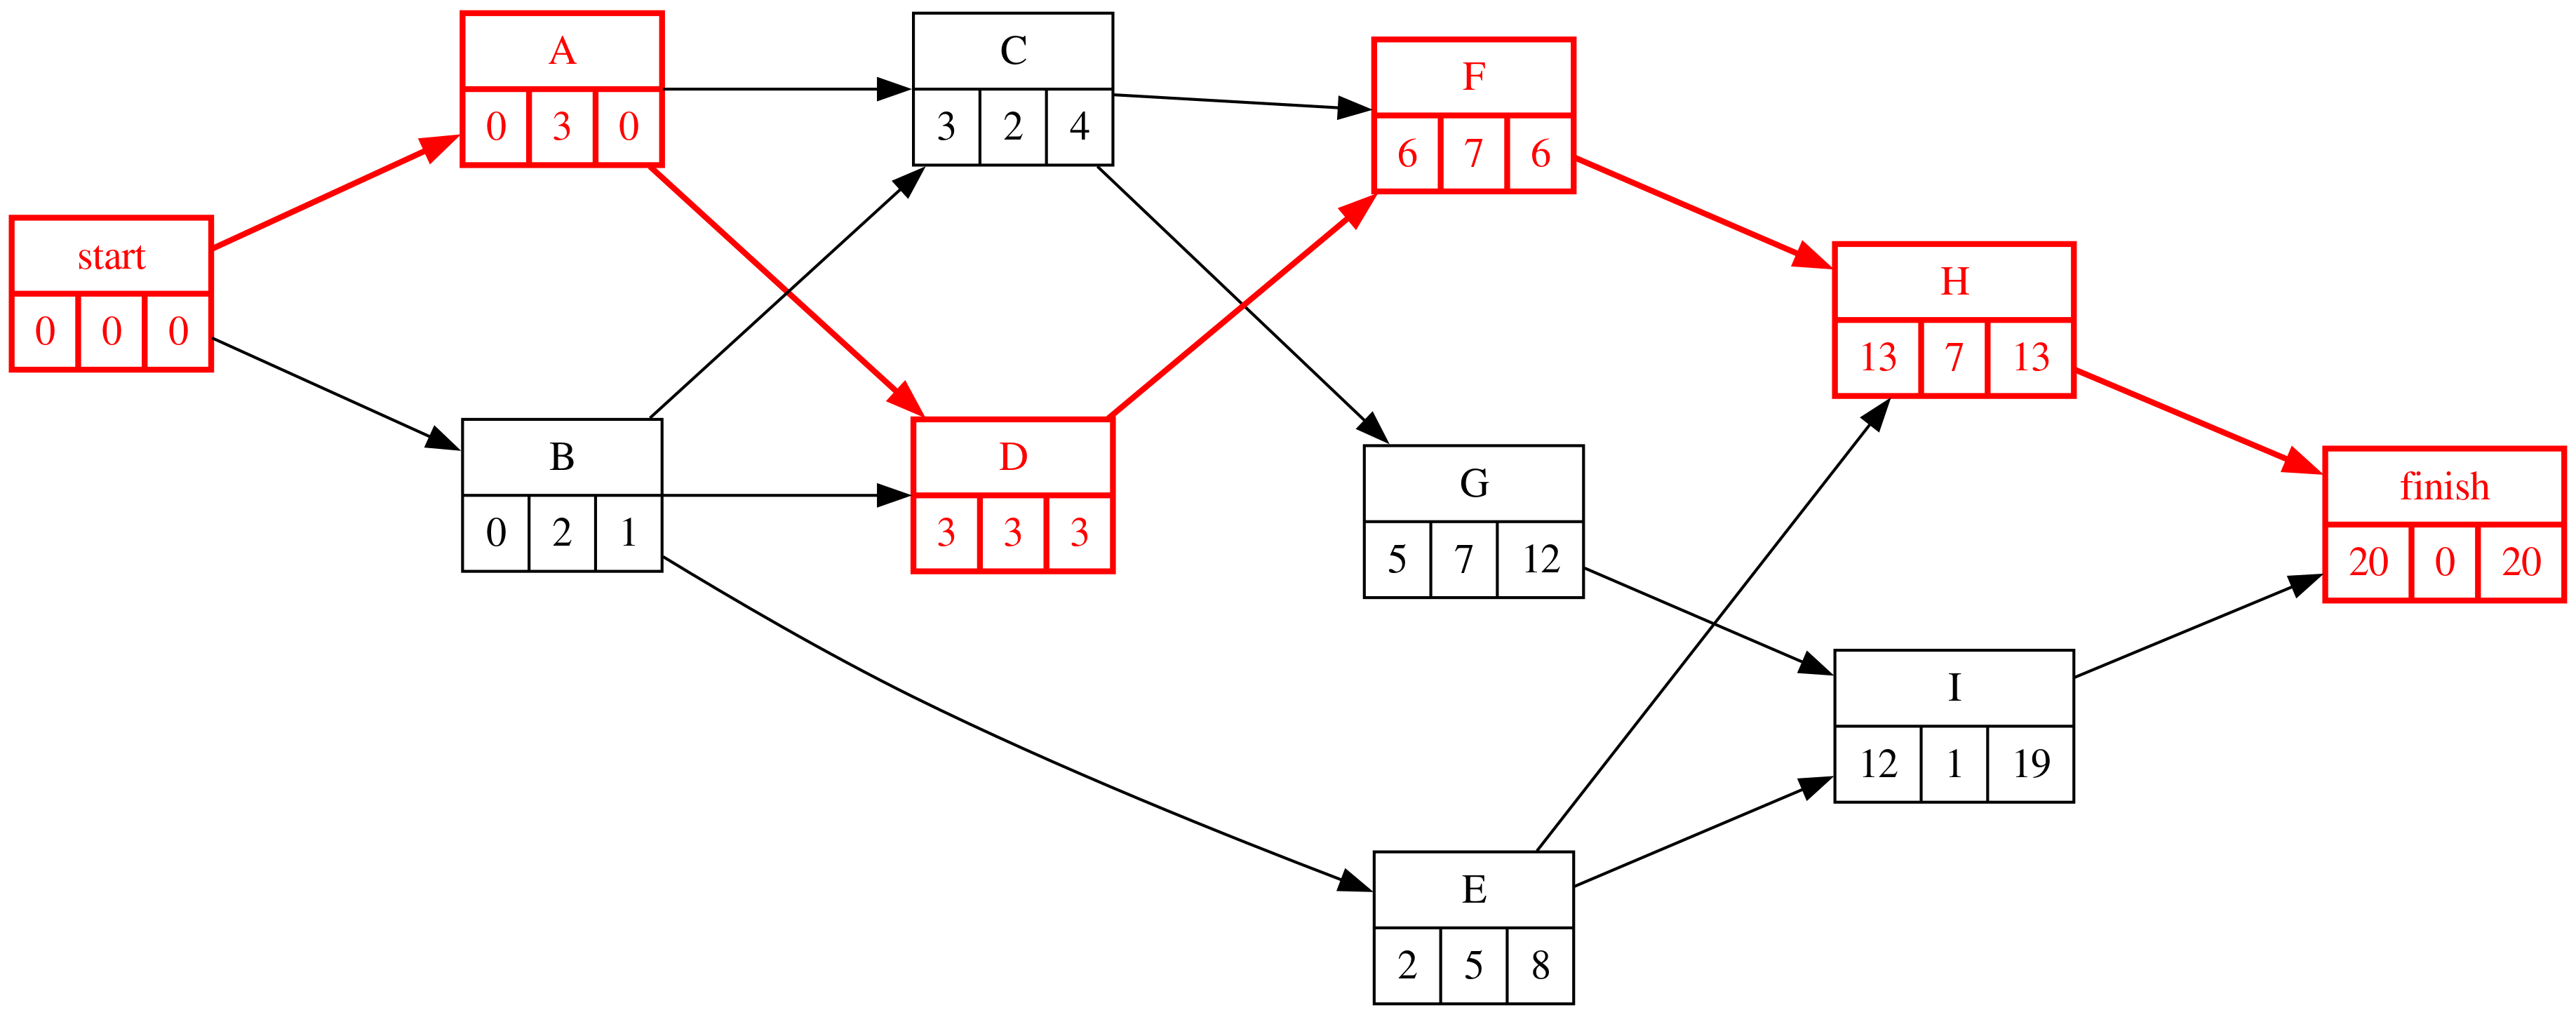

In [9]:
#| fig-cap: "Grafo Roy de la planificación"
#| label: fig-pert
proyecto.display_roy_pasos(datos_proyecto['duration'])

## Apartado 1

In [10]:
display(Markdown(pregunta_1))

1. (A) Calcule PV, EV, AC, CV, SV, CPI y SPI en la semana de control con la versión del informe y con la verificada, actividad a actividad y en total, y la previsión de coste final EAC = BAC / CPI con cada una.  

In [11]:
#| tbl-cap: "PV, EV y AC actividad a actividad con el avance del informe (EV = AC por construcción)"
#| label: tbl-detalleInforme
seg_informe = seguimiento[['actual_duration', 'AC']].assign(performed=seguimiento['performed_informe'])
seg_verificado = seguimiento[['actual_duration', 'AC']].assign(performed=seguimiento['performed_verificado'])
detalle_inf, ind_inf = indicadores(seg_informe, calendario, semana_control)
detalle_ver, ind_ver = indicadores(seg_verificado, calendario, semana_control)
detalle_inf[['BAC', 'planificado hasta la semana', 'PV = BAC·fracción', 'realizado (%)', 'EV = BAC·%', 'AC']]

,BAC,planificado hasta la semana,PV = BAC·fracción,realizado (%),EV = BAC·%,AC
A,20.0,3 de 3,20·1.00 = 20.0,100,20·1.00 = 20.0,20.0
B,70.0,2 de 2,70·1.00 = 70.0,100,70·1.00 = 70.0,70.0
C,50.0,2 de 2,50·1.00 = 50.0,100,50·1.00 = 50.0,50.0
D,40.0,3 de 3,40·1.00 = 40.0,100,40·1.00 = 40.0,40.0
E,20.0,5 de 5,20·1.00 = 20.0,100,20·1.00 = 20.0,20.0
F,60.0,4 de 7,60·0.57 = 34.3,72,60·0.72 = 43.2,43.0
G,50.0,5 de 7,50·0.71 = 35.7,86,50·0.86 = 43.0,43.0
H,40.0,0 de 7,40·0.00 = 0.0,0,40·0.00 = 0.0,0.0
I,70.0,0 de 1,70·0.00 = 0.0,0,70·0.00 = 0.0,0.0


In [12]:
#| tbl-cap: "PV, EV y AC con el avance físico verificado"
#| label: tbl-detalleVerificado
detalle_ver[['BAC', 'planificado hasta la semana', 'PV = BAC·fracción', 'realizado (%)', 'EV = BAC·%', 'AC']]

,BAC,planificado hasta la semana,PV = BAC·fracción,realizado (%),EV = BAC·%,AC
A,20.0,3 de 3,20·1.00 = 20.0,100,20·1.00 = 20.0,20.0
B,70.0,2 de 2,70·1.00 = 70.0,100,70·1.00 = 70.0,70.0
C,50.0,2 de 2,50·1.00 = 50.0,100,50·1.00 = 50.0,50.0
D,40.0,3 de 3,40·1.00 = 40.0,100,40·1.00 = 40.0,40.0
E,20.0,5 de 5,20·1.00 = 20.0,100,20·1.00 = 20.0,20.0
F,60.0,4 de 7,60·0.57 = 34.3,34,60·0.34 = 20.4,43.0
G,50.0,5 de 7,50·0.71 = 35.7,43,50·0.43 = 21.5,43.0
H,40.0,0 de 7,40·0.00 = 0.0,0,40·0.00 = 0.0,0.0
I,70.0,0 de 1,70·0.00 = 0.0,0,70·0.00 = 0.0,0.0


In [13]:
#| tbl-cap: "Indicadores y previsión de coste final con las dos versiones"
#| label: tbl-indicadores
comparacion = pd.DataFrame({'informe (EV = AC)': ind_inf, 'verificado': ind_ver})
comparacion.loc['EAC = BAC / CPI'] = [BAC_total / ind_inf['CPI'], BAC_total / ind_ver['CPI']]
comparacion.loc['VAC = BAC − EAC'] = BAC_total - comparacion.loc['EAC = BAC / CPI']
comparacion.round(3)

,informe (EV = AC),verificado
PV,270.000,270.000
EV,286.200,241.900
AC,286.000,286.000
CV,0.200,-44.100
SV,16.200,-28.100
CPI,1.001,0.846
SPI,1.060,0.896
EAC = BAC / CPI,419.706,496.569
VAC = BAC − EAC,0.294,-76.569


Con el informe, SPI = 1.06 («en plazo o adelantados») y CPI = 1,00; con el avance verificado, SPI = 0.90 y CPI = 0.85, y el coste final previsto pasa de 420 k€ a 497 k€ (77 k€ de sobrecoste). La diferencia está sólo en EV: las actividades en curso (F, G) han gastado más de lo que han avanzado.

## Apartado 2

In [14]:
display(Markdown(pregunta_2))

2. (A) Explique por qué con el método del informe el CPI vale exactamente 1 sea cual sea el sobrecoste, y qué magnitud mide en realidad ese «porcentaje realizado».  

Si el porcentaje realizado se define como AC / BAC, entonces EV = BAC · (AC / BAC) = AC para cada actividad, y por tanto CPI = EV / AC = 1 siempre, con independencia de lo que se haya gastado de más. El «porcentaje realizado» del informe no mide avance: mide **consumo de presupuesto**. Y el SPI del informe compara lo gastado con lo planificado (AC / PV): una actividad que gasta de más aparece como adelantada. El método anula por construcción las dos señales que el valor ganado existe para dar.

## Apartado 3

In [15]:
display(Markdown(pregunta_3))

3. (B) ¿Qué criterio de referencia incumple el informe tal como lo quiere enviar el jefe de proyecto y qué forma de engaño es? ¿Qué cifras tendría que contener el informe para cumplir el criterio?  

**C1 (afirmación falsa).** El informe afirma un avance que el jefe de proyecto sabe que no es el real («sé que lo que hay en obra va algo más lento»); no es una estimación discutible sino un dato que se sabe falso, calculado con un método elegido porque da el resultado deseado. También **C3**: los índices son cifras «ciertas» (salen de los datos) presentadas en un marco —un método de medida que no mide avance— que lleva al comité a una conclusión equivocada. Para cumplir el criterio, el informe debe contener los indicadores con el avance verificado (SPI 0.90, CPI 0.85, EAC 497 k€) y, si se quiere, la versión del informe como «consumo de presupuesto», con su nombre.

In [16]:
preguntas_test = [
    ('Con el método «avance = gastado / presupuesto», el CPI vale…', ['exactamente 1 siempre', 'menos de 1 si hay sobrecoste', 'más de 1 si hay sobrecoste', 'lo mismo que con el avance físico'],
     'EV = BAC·(AC/BAC) = AC, luego CPI = EV/AC = 1 sea cual sea el gasto.'),
    ('Enviar al comité un avance que se sabe inferior al real es, según los criterios de la lección…', ['C1, afirmación falsa', 'C4, retención de información', 'C8, reserva declarada', 'ningún criterio: es una estimación'],
     'Es un dato que quien lo comunica sabe falso; no una omisión ni una estimación.'),
    ('¿Qué indicador cambia entre las dos versiones del informe?', ['sólo EV (y con él CPI y SPI)', 'sólo AC', 'PV y AC', 'ninguno'],
     'PV depende del plan y AC de lo gastado; el porcentaje de avance sólo entra en EV.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Ética 19 — informe maquillado')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_etica.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
from pmule import muestra_test
muestra_test(preguntas_test)

$CATEGORY: Ética 19 — informe maquillado

::Ética 19 — informe maquillado P1::Con el método «avance = gastado / presupuesto», el CPI vale… {=exactamente 1 siempre ~menos de 1 si hay sobrecoste ~más de 1 si hay sobrecoste ~lo mismo que con el avance físico ####EV = BAC·(AC/BAC) = AC, luego CPI = EV/AC = 1 sea cual sea el gasto.}

::Ética 19 — informe maquillado P2::Enviar al comité un avance que se sabe inferior al real es, según los criterios de la lección… {~ningún criterio: es una estimación =C1, afirmación falsa ~C8, reserva declarada ~C4, retención de información ####Es un dato que quien lo comunica sabe falso; no una omisión ni una estimación.}

::Ética 19 — informe maquillado P3::¿Qué indicador cambia entre las dos versiones del informe? {~ninguno =sólo EV (y con él CPI y SPI) ~sólo AC ~PV y AC ####PV depende del plan y AC de lo gastado; el porcentaje de avance sólo entra en EV.}



## Apartado 4

In [17]:
display(Markdown(pregunta_4))

4. (C) Usted firma el informe junto al jefe de proyecto. ¿Qué hace y qué dice a cada parte (jefe de proyecto, comité)? Aplique la rúbrica de la lección.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados y qué pierde o gana cada uno; (2) formular al menos dos alternativas además de la que se propone en el enunciado; (3) someter cada alternativa a las tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería si se hiciera pública?) y reversibilidad (¿la aceptaría en el papel del afectado?)—; (4) decidir y redactar la comunicación con las cifras del bloque A. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Un camino defendible: no firmar el informe con el método del gasto; proponer al jefe de proyecto enviar el avance verificado con una nota de método (quién lo midió y cómo) y un plan de recuperación para las actividades en curso; si se niega, hacer constar por escrito la discrepancia (44 k€ de valor declarado y no ejecutado) y elevarla a quien corresponda en la organización. Al comité: los índices verificados, el EAC de 497 k€ y las medidas. Lo que no cabe: firmar y «ya lo corregiremos el mes que viene» (publicidad: ¿defendería ese informe si el comité supiera cómo se ha calculado?).